# # 04 · The modern decoder-only recipe (LLaMA / Mistral / Qwen style)
#
# Today's open LLMs are still GPT-shaped, but almost every component was swapped for a better one:
#
# | GPT-2 | → | LLaMA-style |
# |---|---|---|
# | LayerNorm (+bias) | → | **RMSNorm** (no mean, no bias) |
# | learned absolute positions | → | **RoPE** rotary positions inside attention |
# | GELU MLP (4d) | → | **SwiGLU** gated MLP (≈ 8/3 d) |
# | multi-head attention | → | **GQA** grouped-query attention (fewer KV heads) |
# | biases everywhere | → | no biases |
#
# Below we build both from the same `DecoderLM` shell and compare them at (nearly) equal parameter count.

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 1200
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

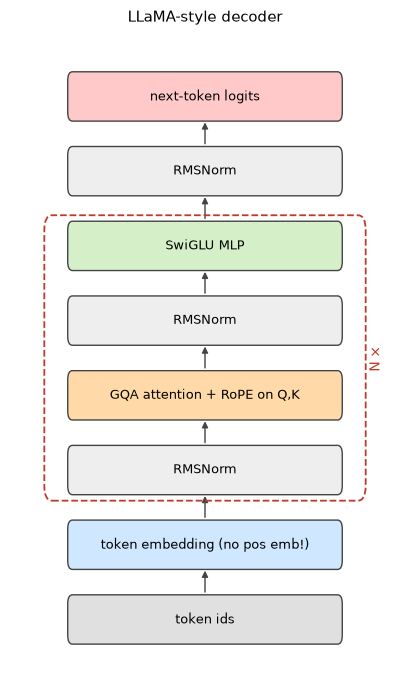

In [2]:
block_diagram([("next-token logits", "out"), ("RMSNorm", "norm"), ("SwiGLU MLP", "ffn*"), ("RMSNorm", "norm*"), ("GQA attention + RoPE on Q,K", "attn*"),
               ("RMSNorm", "norm*"), ("token embedding (no pos emb!)", "embed"), ("token ids", "other")][::-1], title="LLaMA-style decoder", repeat="N ×")

# ## The building blocks

In [3]:
show_source(RMSNorm, SwiGLU, rope_cos_sin, apply_rope)

```python
class RMSNorm(nn.Module):
    """LLaMA-style norm: x / rms(x) * g  (no mean subtraction, no bias)."""
    def __init__(self, d, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

```
```python
class SwiGLU(nn.Module):
    """Gated MLP: down( silu(gate(x)) * up(x) ). hidden ~ 8/3 d keeps the parameter count of a 4d GELU MLP."""
    def __init__(self, d, hidden=None):
        super().__init__(); hidden = hidden or int(8 * d / 3)
        self.gate = nn.Linear(d, hidden, bias=False); self.up = nn.Linear(d, hidden, bias=False)
        self.down = nn.Linear(hidden, d, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

```
```python
def rope_cos_sin(T, hd, base=10000.0, device=None):
    inv = 1.0 / (base ** (torch.arange(0, hd, 2, device=device).float() / hd))
    ang = torch.outer(torch.arange(T, device=device).float(), inv)          # (T, hd/2)
    return ang.cos(), ang.sin()

```
```python
def apply_rope(x, cos, sin):
    """x: (B, H, T, hd). Rotate each (even, odd) pair by a position-dependent angle."""
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)
    return out.flatten(-2)

```

# ### RMSNorm vs LayerNorm

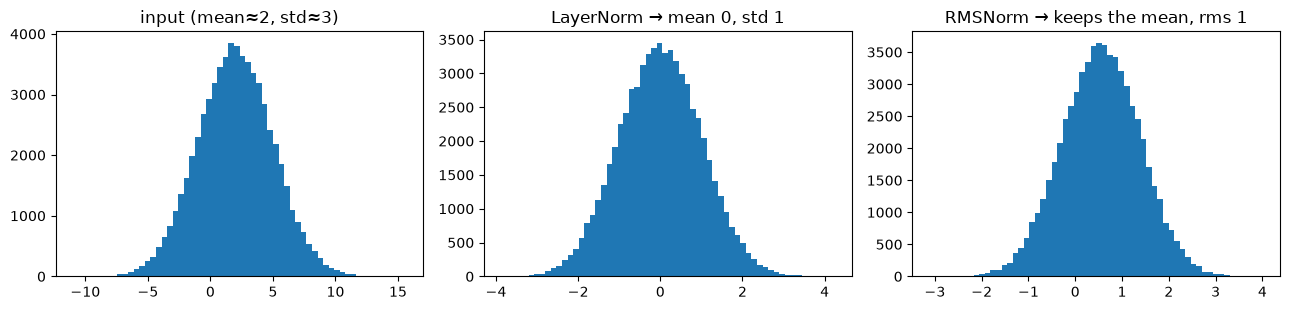

In [4]:
x = torch.randn(1000, 64) * 3 + 2
ln, rn = nn.LayerNorm(64)(x), RMSNorm(64)(x)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(x.flatten(), bins=60); ax[0].set_title("input (mean≈2, std≈3)")
ax[1].hist(ln.flatten().detach(), bins=60); ax[1].set_title("LayerNorm → mean 0, std 1")
ax[2].hist(rn.flatten().detach(), bins=60); ax[2].set_title("RMSNorm → keeps the mean, rms 1")
plt.tight_layout(); plt.show()

# ### SwiGLU vs GELU

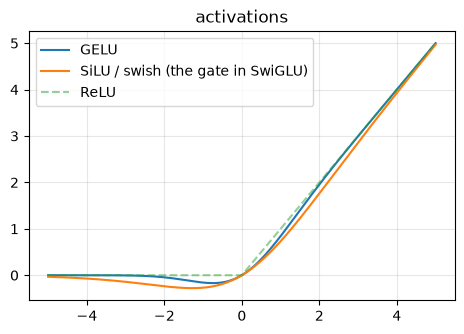

In [5]:
z = torch.linspace(-5, 5, 400)
plt.figure(figsize=(5.5, 3.5)); plt.plot(z, F.gelu(z), label="GELU"); plt.plot(z, F.silu(z), label="SiLU / swish (the gate in SwiGLU)"); plt.plot(z, F.relu(z), "--", label="ReLU", alpha=.5)
plt.legend(); plt.grid(alpha=.3); plt.title("activations"); plt.show()

# ### RoPE: positions as rotations
# Each pair of channels is rotated by angle `pos · θ_i`, with different θ_i per pair (fast → slow). The dot-product
# `q_m · k_n` then depends only on the **relative distance m − n**.

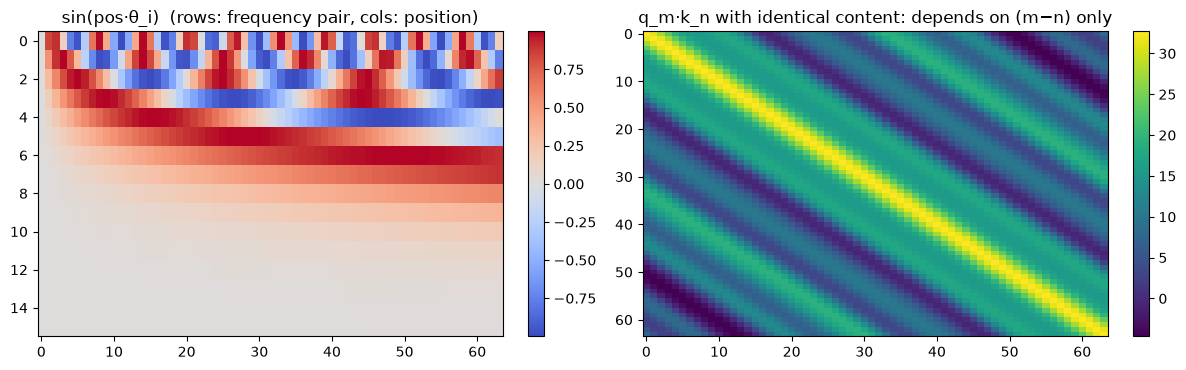

Toeplitz check (diagonals constant): True


In [6]:
hd, T = 32, 64; cos, sin = rope_cos_sin(T, hd)
ang = torch.atan2(sin, cos)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_heatmap(sin.T, title="sin(pos·θ_i)  (rows: frequency pair, cols: position)", ax=ax[0], cmap="coolwarm")
q = torch.randn(1, 1, 1, hd).expand(1, 1, T, hd).contiguous(); k = q.clone()
qr, kr = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
score = (qr[0, 0] @ kr[0, 0].T)                       # same content everywhere -> only position matters
plot_heatmap(score, title="q_m·k_n with identical content: depends on (m−n) only", ax=ax[1])
plt.tight_layout(); plt.show()
print("Toeplitz check (diagonals constant):", torch.allclose(score[10, 5], score[30, 25], atol=1e-4))

# ## Build both models

In [7]:
d, H = 96, 4
def gpt2_like():
    return DecoderLM(V, d, [Block(d, Attention(d, H, bias=True), GELUMLP(d), norm=nn.LayerNorm) for _ in range(3)], norm=nn.LayerNorm, learned_pos=128)
def llama_like(kv=2):
    return DecoderLM(V, d, [Block(d, Attention(d, H, n_kv_head=kv, rope=True, bias=False), SwiGLU(d), norm=RMSNorm) for _ in range(3)])
m_gpt, m_llama = gpt2_like(), llama_like()
print(f"GPT-2-like : {count_params(m_gpt):,} params\nLLaMA-like : {count_params(m_llama):,} params")
_ = show_summary(m_llama, input_data=torch.randint(0, V, (1, 64)), depth=2)

GPT-2-like : 354,240 params
LLaMA-like : 311,040 params
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
DecoderLM                                [1, 64]                   [1, 64, 65]               --
├─Embedding: 1-1                         [1, 64]                   [1, 64, 96]               6,240
├─ModuleList: 1-2                        --                        --                        --
│    └─Block: 2-1                        [1, 64, 96]               [1, 64, 96]               101,568
│    └─Block: 2-2                        [1, 64, 96]               [1, 64, 96]               101,568
│    └─Block: 2-3                        [1, 64, 96]               [1, 64, 96]               101,568
├─RMSNorm: 1-3                           [1, 64, 96]               [1, 64, 96]               96
├─Linear: 1-4                            [1, 64, 96]               [1, 64, 65]               6,240
Total params: 317,280
Trainable params: 317,280
Non-tr

# ## Train both for the same number of steps

== GPT-2-like


step  200 | train 2.389 | val 2.366 | 2s


step  400 | train 1.995 | val 2.097 | 5s


step  600 | train 1.870 | val 1.984 | 7s


step  800 | train 1.715 | val 1.876 | 10s


step 1000 | train 1.705 | val 1.819 | 12s


... (3 outputs left out)

step  600 | train 1.614 | val 1.818 | 9s


step  800 | train 1.512 | val 1.735 | 12s


step 1000 | train 1.535 | val 1.672 | 14s


step 1200 | train 1.450 | val 1.652 | 17s


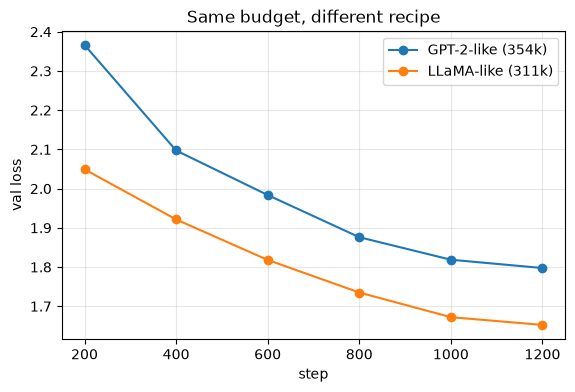

In [8]:
res = {}
for name, m in [("GPT-2-like", m_gpt), ("LLaMA-like", m_llama)]:
    print("==", name); set_seed(0); res[name] = train_lm(m, train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=200)
save_result("04 LLaMA-style decoder (RMSNorm+RoPE+SwiGLU+GQA)", m_llama, res["LLaMA-like"])
fig, ax = plt.subplots(figsize=(6.5, 4))
for n, h in res.items(): ax.plot(h["val_step"], h["val"], "o-", label=f"{n} ({count_params(m_gpt if n.startswith('GPT') else m_llama)/1e3:.0f}k)")
ax.set(xlabel="step", ylabel="val loss", title="Same budget, different recipe"); ax.legend(); ax.grid(alpha=.3); plt.show()

# ## Sample from the LLaMA-style model

In [9]:
start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(data["decode"](generate(m_llama, start, 400, temperature=0.8, top_k=10, block_size=128)[0].tolist()))


To with in the devil be dranio, when he would slander,
The crown and be men.

MONTAGoline thy day; wholee make warden morroughtere be mostrievonevakendit wentieentitutto mon who,
Alestandereatend whathereedieveliusealray lowariten ther,
Wan nowert theedealy offesteer wel selfeliestellow to and off allandess arts hown thin to denot willowiniereth,
There thatorde lovethesuticulakentercumblameed,
To 


# ## GQA attention maps: 4 query heads share 2 KV heads
# Heads (0,1) read the same keys/values, heads (2,3) read the others — yet they still attend differently.

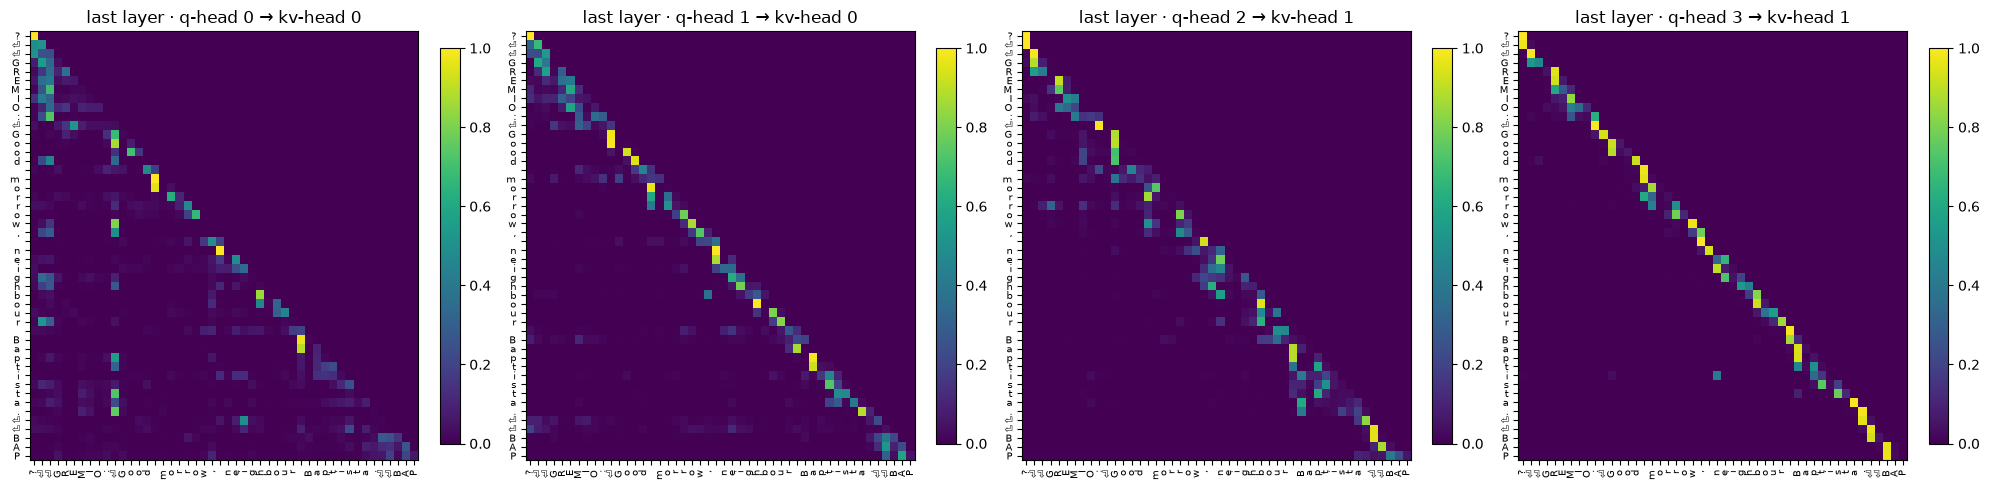

In [10]:
ids = val[:48][None].to(device); txt = [("⏎" if c == "\n" else c) for c in data["decode"](val[:48].tolist())]
for b in m_llama.blocks: b.mixer.keep_attn = True
m_llama.eval(); m_llama(ids)
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for h in range(4): plot_heatmap(m_llama.blocks[2].mixer.last_attn[0, h].cpu(), txt, txt, f"last layer · q-head {h} → kv-head {h // 2}", ax=axs[h])
plt.tight_layout(); plt.show()